# Signed Networks
In this chapter we will:

1. Define signed networks
2. Explore how and why signed networks are special
3. Translate basic network measures to signed networks 

*Acknowledgement: This chapter relies on \_\_\_\_\_\_\_\_\_\_ from \_\_\_\_\_\_\_\_\_\_.*
__________

## Plan
*For the intermediate presentations on Monday, Oct 19.* Before then, fill in this section: the problem your chapter tackles, and a table of contents listing the sections you plan, what each will contain, and the key references for it. You'll present from this notebook, scrolling through this plan. Keep it in your final chapter, and update it as your plan changes.

**The problem:** Regular (unsigned) networks use edges to denote the relationships that exist between nodes. However, while these edges indicate the presence of a relationship, they provide no way to characterize *opposite* relations. In contrast, many real networks have nodes with opposing relations,  or relations characterized by *conflict*. For example, in social networks people often have both friendly relations and antagonistic relations. Countries can be allies or enemies. Neurons can excite or inhibit one another[1](cite). 

This conflict is denoted by negative links in a network. Negative links do more than just include information opposing relationships: the interaction of positive and negative links fundamentally impacts the structure and dynamics of the underlying network [2](cite). Thus, examining only positive links or only negative links misses a vital component of complexity.

Unfortunately, the inclusion of negative links introduces mathematical complications for many of the measures traditionally used to analyze networks, such as degree distribution, clustering, path distance, and community detection[1](cite). It also creates necessity for new measures, such as balance. In this lesson, we will discuss the utility of signed networks, explore how many of these measures are translated to analyze signed networks, and acknowledge the gaps and limitations that still remain in the emerging field. 

**Table of contents:**
1. **Introduction to Signed Networks**
    - What are signed networks?
    - Properties of Signed Networks
    - Basic notation
    - Applications of signed networks 

2. **Basic Network Measures**:
    - Overview of basic challenges for measures of signed networks
    - Start with degree distribution: how is it different?
    - Implement degree distribution for signed networks
    - Briefly touch on how the measures for clustering, centrality, and community detection differ (maybe implement in advanced topics section?)

3. **Balance**: 
    - A brief history of Heidarian and Hararian balance
    - Practical Exercise: 
        - Hararian theorem: for a small network, code that looks at every path
        - *Your turn*: Implement Hararian Theorem 1
    - Code implementation of degree of balance 

4. **Limitations**:
    - Discuss current challenges with signed networks
    - Identify major gaps in the literature

5. **References**

__________

In [7]:
# import your packages! and whatever else that's basic that you need
# If you need a package that isn't in our course environment (cmns-core), say which one
# and how to install it, here at the top.
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
rc('axes', fc='w')
rc('figure', fc='w')
rc('savefig', fc='w')
rc('axes', axisbelow=True)

## Signed Networks: An Introduction

Provide a broad overview of your topic: the paper(s) that introduced it, and how (or whether) it's used in network science today. Include lots of citations!! This should be a thorough introduction to the topic you're sharing with us. If possible, use figures, equations, or provide links to relevant outside content.

See some of the [markdown + equations](https://jupyterbook.org/en/stable/content/math.html) tutorials here. From that link: To insert in-line math use the `$` symbol within a Markdown cell. For example, the text `$this_{is}^{inline}$` will produce: $this_{is}^{inline}$.

Adding `$$ equation stuff $$` on a new line makes the equation centered.
________

#### The hook: Some type of exciting example of signed networks

How do we represent conflict?!

![](https://cdn1.faroutmagazine.co.uk/uploads/1/2023/06/Bruce-Lee-Chuck-Norris-Fight-Far-Out-Magazine-F.jpg)

*Source: [Far Out Magazine](https://faroutmagazine.co.uk/bruce-lee-illegally-fought-chuck-norris/)*

### What is a signed network?

A signed network is a network with both positive and negative edges:

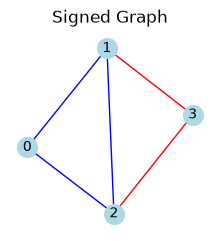

In [49]:
G = nx.Graph()
G.add_nodes_from([0, 1, 2, 3])
G.add_nodes_from([0, 1, 2, 3])

signed_edges = [
    (0, 1, {"sign": 1}),
    (0, 2, {"sign": 1}),
    (1, 2, {"sign": 1}),
    (2, 3, {"sign": -1}),
    (3, 1, {"sign": -1}),
]
G.add_edges_from(signed_edges)

# Visualize it
edge_colors = [
    "blue" if attrs["sign"] == 1 else "red" for u, v, attrs in G.edges(data=True)
]

plt.figure(figsize=(2, 2))
nx.draw(
    G,
    with_labels=True,
    node_color="lightblue",
    edge_color=edge_colors,
    node_size=200,
    font_size=10,
)
plt.title("Signed Graph")
plt.show()

And some more overview of signed networks!

### Properties of Signed Networks

- Must account for both negative and positive edges
- How these influence each other
- Issues with math on signed networs

### Basic Notation

- Adjacency matrix
- Matrices A+ and A-  

### Common Applications 
- Social Networks (where this comes from!)
- Neurons (brain networks)
- Proteins
- Etc

### I want your chapter to showcase your ability to distill the following:
1. Your understanding of a topic not covered in class
2. Your accuracy in creating *correct* code around your topic, along with a strong reference list
3. Your ability to convey your understanding via:
    - A) Chunking the information into a single lesson that builds on itself (e.g. breaking down complex functions into parts, putting the pieces together, using different examples to illustrate your methods)
    - B) Good examples / visuals / writeups of what results produced during the lesson / datasets used to illustrate your concept
    - C) At least one interactive component (i.e., the "Your Turn!" in our lessons)
4. An honest account of your method's limitations: where it breaks, and what it can't tell us

Much like in our lessons, it's okay to include more than you imagine covering in a (hypothetical) 100-minute class period. Be sure to indicate what sections of your chapter are "advanced topics", and always include relevant citations or motivation.

In [3]:
def how_to_write_a_function(inputs):    
    """
    Always. Include. A. Docstring! Remember, you will use this one day! "Future 
    You" does not understand the random code snippets you wrote a year ago. Help
    Future You out by thoroughly describing the...


    Parameters
    ----------
    inputs : input type (e.g. array, list, graph, etc)
        Describe the input briefly here


    Returns
    -------
    var_out : variable type 
        Describe the output!


    Notes
    -----
    - Especially if there's certain things to be aware of...
    - ...make notes about this!


    Time Complexity
    ---------------
    (optional)


    Citations
    ---------
    Hartle, Klein, McCabe, Daniels, St-Onge, Murphy, & Hébert-Dufresne (2020).
    Network comparison and the within-ensemble graph distance. *Proceedings of
    the Royal Society A*, 476(2243), 20190744. doi: https://doi.org/10.1098/rspa.2019.0744.

    Among others...


    Example (optional)
    -------
    >>> import networkx as nx
    >>> G = nx.path_graph(4)
    >>> closeness_centrality_from_scratch(G)
    {0: 0.6666666666666666, 1: 1.0, 2: 1.0, 3: 0.6666666666666666}
    """

    # include brief but informative comments!

    pass

In [4]:
# show quick short examples of your function in action
x = 20
print(how_to_write_a_function(x))

None


__________
### You could add some graphics from articles or other tutorials!

![](https://s3.amazonaws.com/pix.iemoji.com/images/emoji/apple/ios-12/256/soccer-ball.png)

*Source: Unicode Foundation*

***And always make sure to cite/attribute any source you use.***

### When you show examples that involve plotting data, make terrific figures
This includes labeled axes, a legend if you plot more than one thing, font sizes big enough to read, and a title or caption that says what we're looking at.

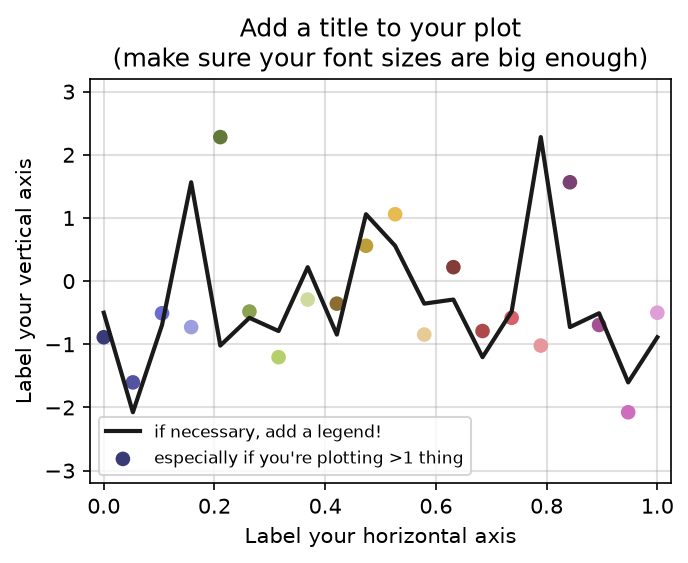

In [5]:
w = 5.0
h = 3.5
fig, ax = plt.subplots(1, 1, figsize=(w,h), dpi=150)

x = np.linspace(0,1,20)
y = np.random.normal(0,1,20)

ax.plot(x,y, label='if necessary, add a legend!', color='.1', lw=2)
ax.scatter(x, y[::-1], label="especially if you're plotting >1 thing",
           c=plt.cm.tab20b(x))

ax.legend(fontsize='small')

# sometimes I like to add gridlines to guide the eyes
ax.grid(lw=1.0, alpha=0.3, color='.6')

ax.set_title('Add a title to your plot\n(make sure your font sizes are big enough)')
ax.set_xlabel('Label your horizontal axis')
ax.set_ylabel('Label your vertical axis')

ax.set_xlim(-0.025,1.025)
ax.set_ylim(-3.2,3.2)


plt.show()

### Your turn!
Include at least one exercise like the ones in our class notebooks: a short prompt, and an empty cell for the reader to fill in. We may try yours during your presentation.

In [ ]:
# Your Turn!

## Limitations
Where does this method break, and what can't it tell us? Say so plainly, with an example if you can.

## Logistics

This final project will require a substantial amount of time to accomplish. Making these lessons takes a lot of time, and it happens over weeks and months. You are all very talented and accomplished students, but I suspect it will be hard to do this entirely on your own.

I recommend the following:
1. Reach out to me to share ideas and progress **multiple times** between now and December. I can help you find the relevant literature and decide what to include in your chapter.
2. Share your progress with your classmates, both inside and outside of this class.

Dates, submission, and grading are on the Final Project and Intermediate Project Presentations assignments on Canvas. Before you submit, keep your chapter in the `final_project/` folder of your fork (with its own `images/` and `data/` subfolders if it needs them), then restart the kernel and run the notebook from top to bottom.

_______

## References and further resources:

1. Ref 1, useful website, etc.
2. Hartle, Klein, McCabe, Daniels, St-Onge, Murphy, & Hébert-Dufresne (2020). Network comparison and the within-ensemble graph distance. *Proceedings of the Royal Society A*, 476(2243), 20190744. doi: https://doi.org/10.1098/rspa.2019.0744.
3. etc
4. etc

(Aim for 10+ useful citations)